Setup and image upload

Saving seishiro.jpeg to seishiro (1).jpeg


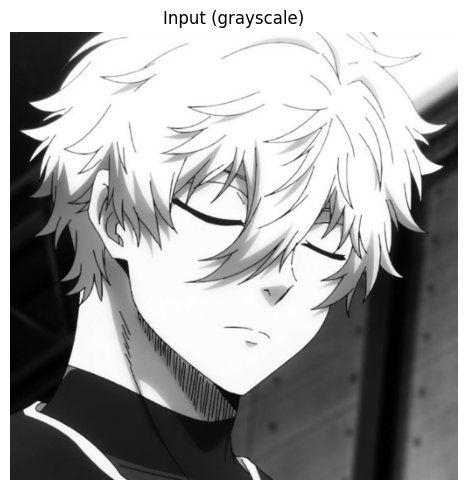

In [2]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files

# Upload any image (jpg/png) when prompted
uploaded = files.upload()
path = list(uploaded.keys())[0]

img_color = cv2.imread(path)
img = cv2.cvtColor(img_color, cv2.COLOR_BGR2GRAY)   # grayscale version used in all tasks
img = cv2.resize(img, (512, 512))                   # fixed size so two-image operations work

def show(images, titles, cols=3, save_as=None, figsize=(15, 9)):
    """Display images in a grid; optionally save the figure as a screenshot."""
    rows = int(np.ceil(len(images) / cols))
    plt.figure(figsize=figsize)
    for i, (im, t) in enumerate(zip(images, titles)):
        plt.subplot(rows, cols, i + 1)
        plt.imshow(im, cmap='gray', vmin=0, vmax=255)
        plt.title(t)
        plt.axis('off')
    plt.tight_layout()
    if save_as:
        plt.savefig(save_as, dpi=150)
    plt.show()

show([img], ["Input (grayscale)"], cols=1, figsize=(5, 5))

1. Histogram equalization and equalizer

Manual and OpenCV results identical: False


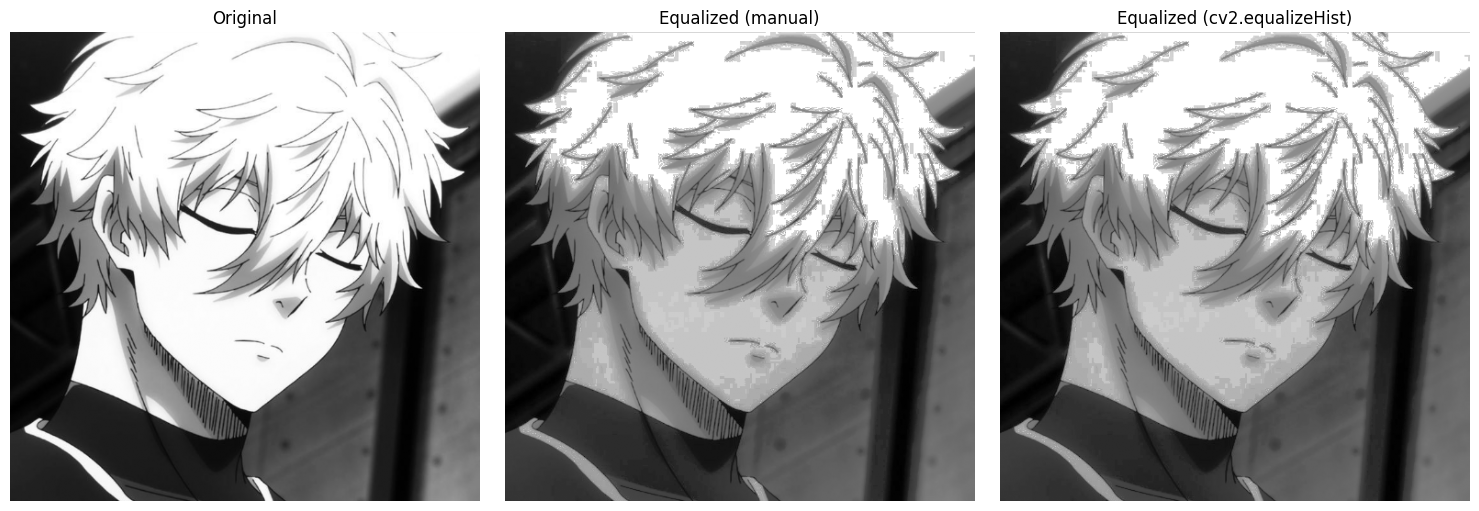

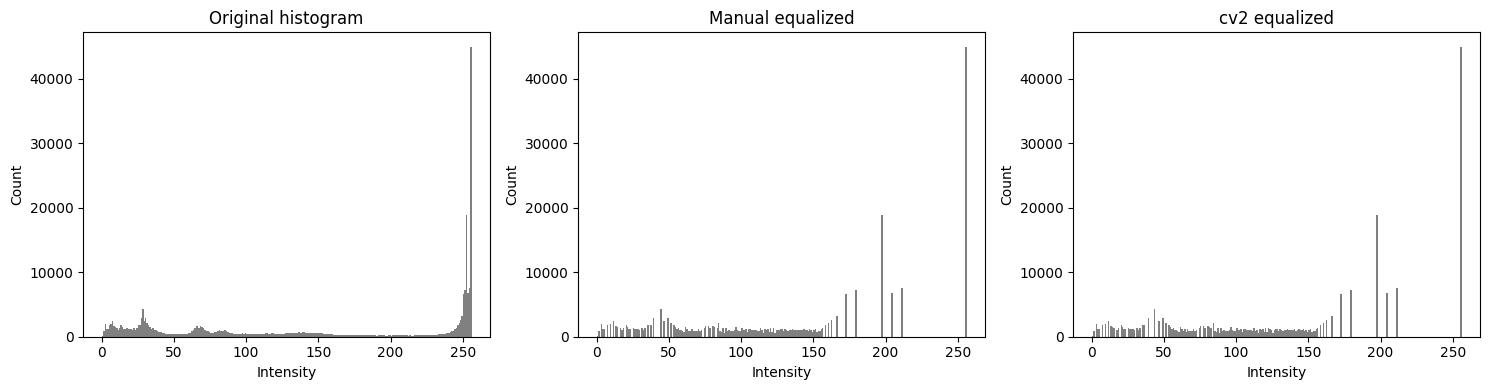

In [3]:
# ---- Manual histogram equalization ----
hist = np.bincount(img.ravel(), minlength=256)   # histogram h(r_k)
pdf  = hist / img.size                           # probability p(r_k)
cdf  = np.cumsum(pdf)                            # cumulative distribution
s    = np.round(255 * cdf).astype(np.uint8)      # transformation s_k = 255 * CDF
eq_manual = s[img]                               # apply mapping to every pixel

# ---- Built-in equalizer (for comparison) ----
eq_cv = cv2.equalizeHist(img)

print("Manual and OpenCV results identical:", np.array_equal(eq_manual, eq_cv))

# Images
show([img, eq_manual, eq_cv],
     ["Original", "Equalized (manual)", "Equalized (cv2.equalizeHist)"],
     save_as="task1_images.png", figsize=(15, 5))

# Histograms
plt.figure(figsize=(15, 4))
for i, (im, t) in enumerate(zip([img, eq_manual, eq_cv],
                                ["Original histogram", "Manual equalized", "cv2 equalized"])):
    plt.subplot(1, 3, i + 1)
    plt.hist(im.ravel(), bins=256, range=(0, 256), color='gray')
    plt.title(t); plt.xlabel("Intensity"); plt.ylabel("Count")
plt.tight_layout()
plt.savefig("task1_histograms.png", dpi=150)
plt.show()

2. AND, OR, NOT

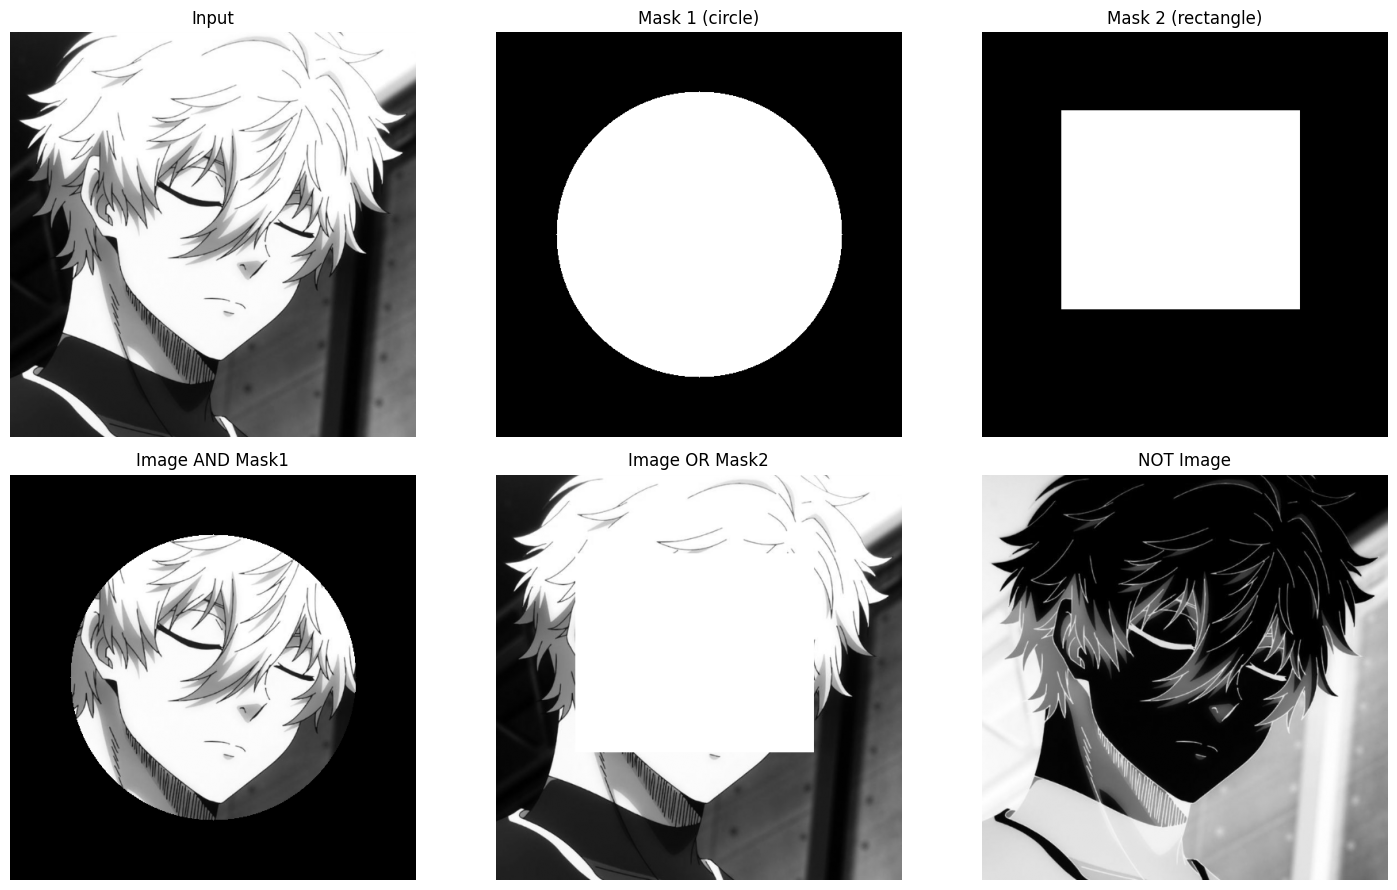

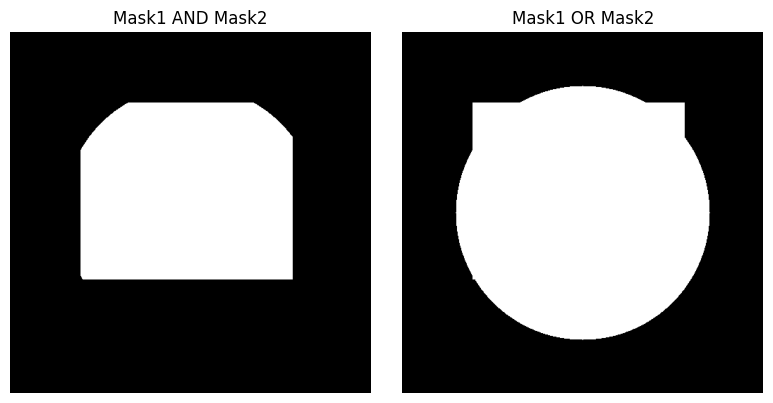

In [4]:
h, w = img.shape

# Binary mask: white circle on black background
mask1 = np.zeros((h, w), np.uint8)
cv2.circle(mask1, (w // 2, h // 2), 180, 255, -1)

# Second mask: white rectangle on black background
mask2 = np.zeros((h, w), np.uint8)
cv2.rectangle(mask2, (100, 100), (400, 350), 255, -1)

# Logical operations
and_res    = cv2.bitwise_and(img, img, mask=mask1)   # image AND circle mask
or_res     = cv2.bitwise_or(img, mask2)              # image OR rectangle mask
not_res    = cv2.bitwise_not(img)                    # negative of image
and_masks  = cv2.bitwise_and(mask1, mask2)           # mask AND mask
or_masks   = cv2.bitwise_or(mask1, mask2)            # mask OR mask

show([img, mask1, mask2, and_res, or_res, not_res],
     ["Input", "Mask 1 (circle)", "Mask 2 (rectangle)",
      "Image AND Mask1", "Image OR Mask2", "NOT Image"],
     cols=3, save_as="task2_logic.png")

show([and_masks, or_masks], ["Mask1 AND Mask2", "Mask1 OR Mask2"],
     cols=2, figsize=(8, 4))

3. Four arithmetic operations

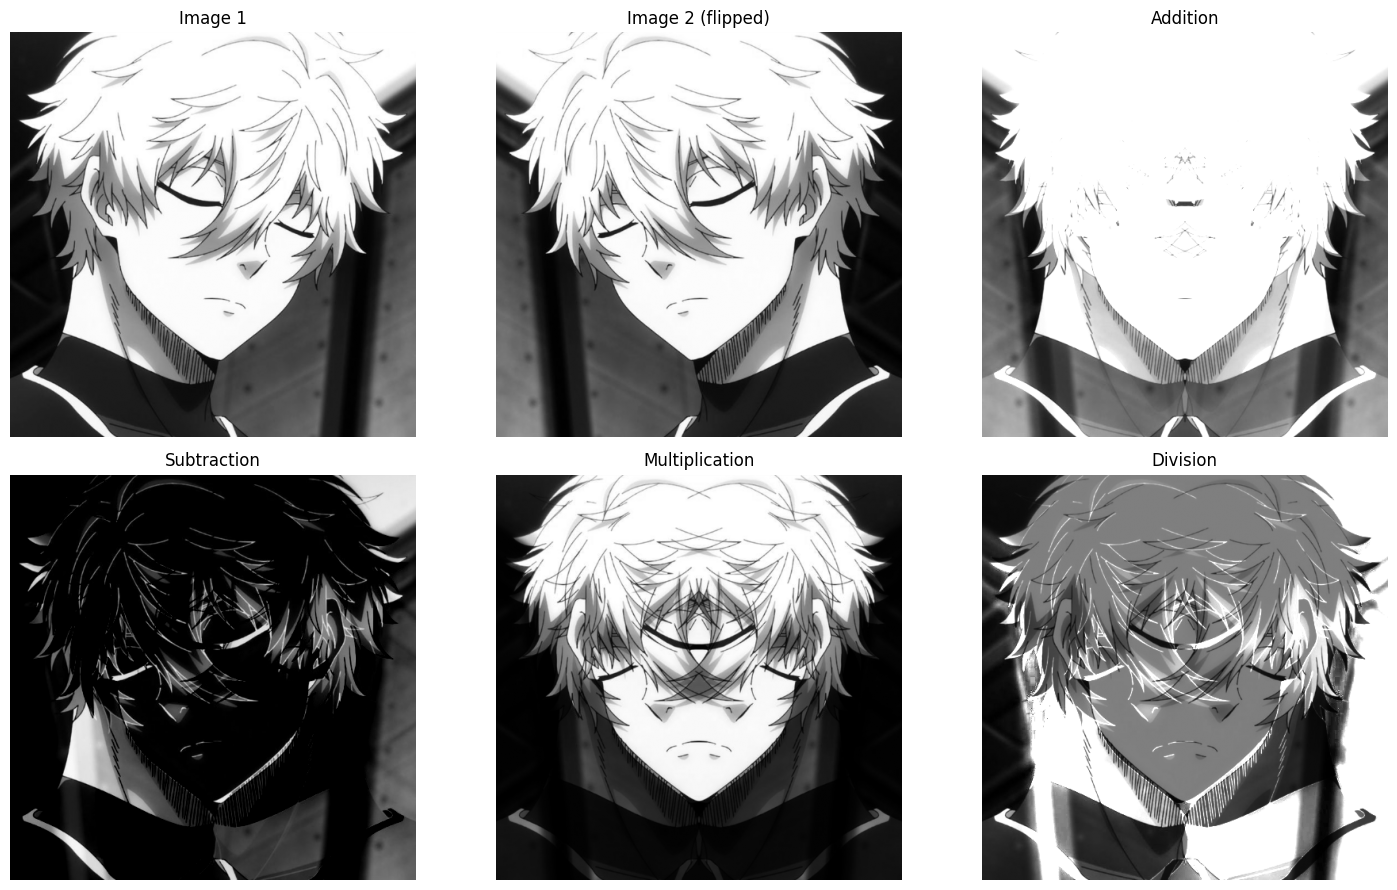

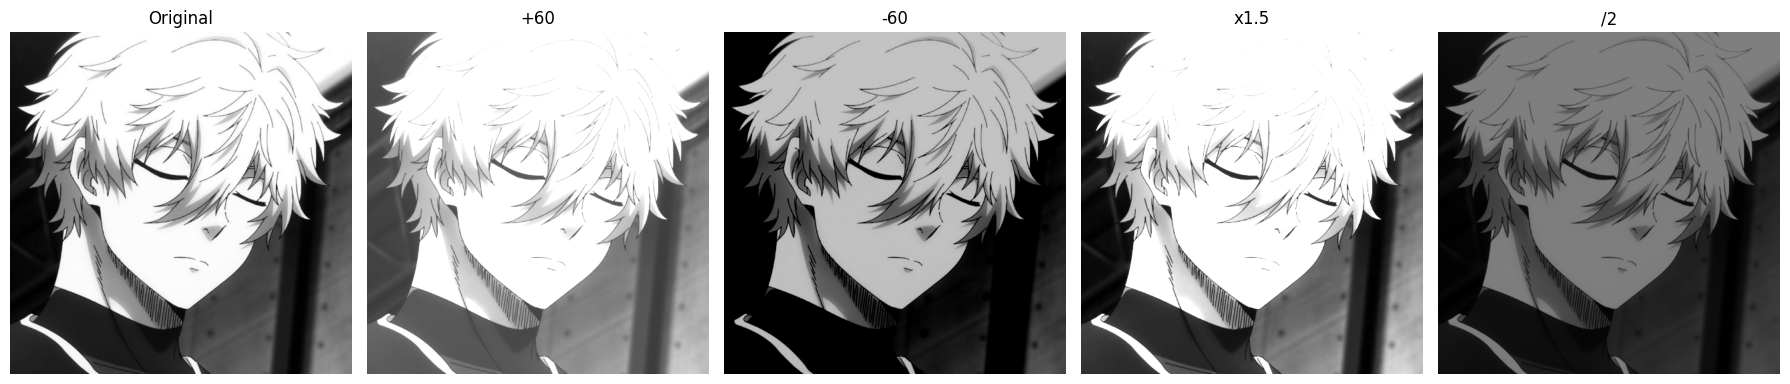

In [5]:
# Second image: a flipped copy, so the operations have two different operands
img2 = cv2.flip(img, 1)

# Addition and subtraction (saturated to 0-255)
add_res = cv2.add(img, img2)
sub_res = cv2.subtract(img, img2)

# Multiplication: normalize to 0-1, multiply, scale back
mul_res = np.clip((img / 255.0) * (img2 / 255.0) * 255, 0, 255).astype(np.uint8)

# Division: +1 avoids division by zero; scaled so the result is visible
div_res = np.clip(img.astype(np.float32) / (img2.astype(np.float32) + 1) * 128,
                  0, 255).astype(np.uint8)

show([img, img2, add_res, sub_res, mul_res, div_res],
     ["Image 1", "Image 2 (flipped)", "Addition", "Subtraction",
      "Multiplication", "Division"],
     cols=3, save_as="task3_arithmetic.png")

# Arithmetic with a constant (brightness/contrast changes)
add_c = cv2.add(img, 60)                                    # brighter
sub_c = cv2.subtract(img, 60)                               # darker
mul_c = np.clip(img.astype(np.float32) * 1.5, 0, 255).astype(np.uint8)   # more contrast
div_c = (img / 2).astype(np.uint8)                          # dimmer

show([img, add_c, sub_c, mul_c, div_c],
     ["Original", "+60", "-60", "x1.5", "/2"],
     cols=5, save_as="task3_constant.png", figsize=(18, 4))

4. Spatial filters (a to f)

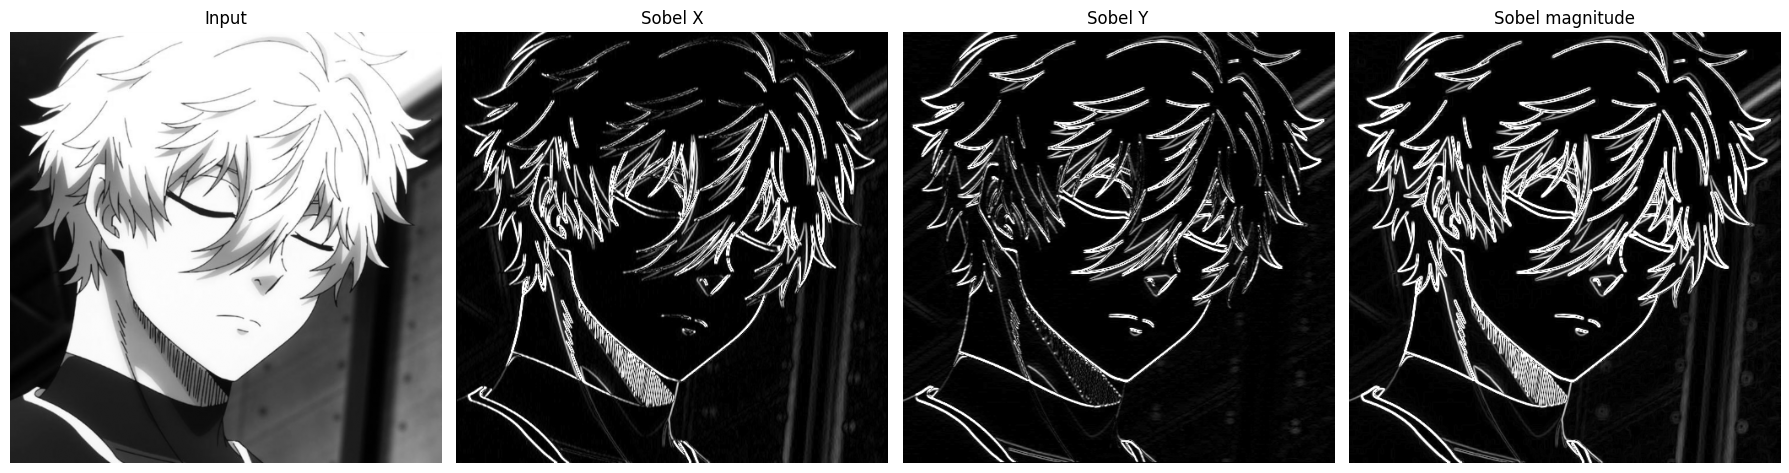

Gaussian mask (5x5, sigma=1):
 [[0.003  0.0133 0.0219 0.0133 0.003 ]
 [0.0133 0.0596 0.0983 0.0596 0.0133]
 [0.0219 0.0983 0.1621 0.0983 0.0219]
 [0.0133 0.0596 0.0983 0.0596 0.0133]
 [0.003  0.0133 0.0219 0.0133 0.003 ]]


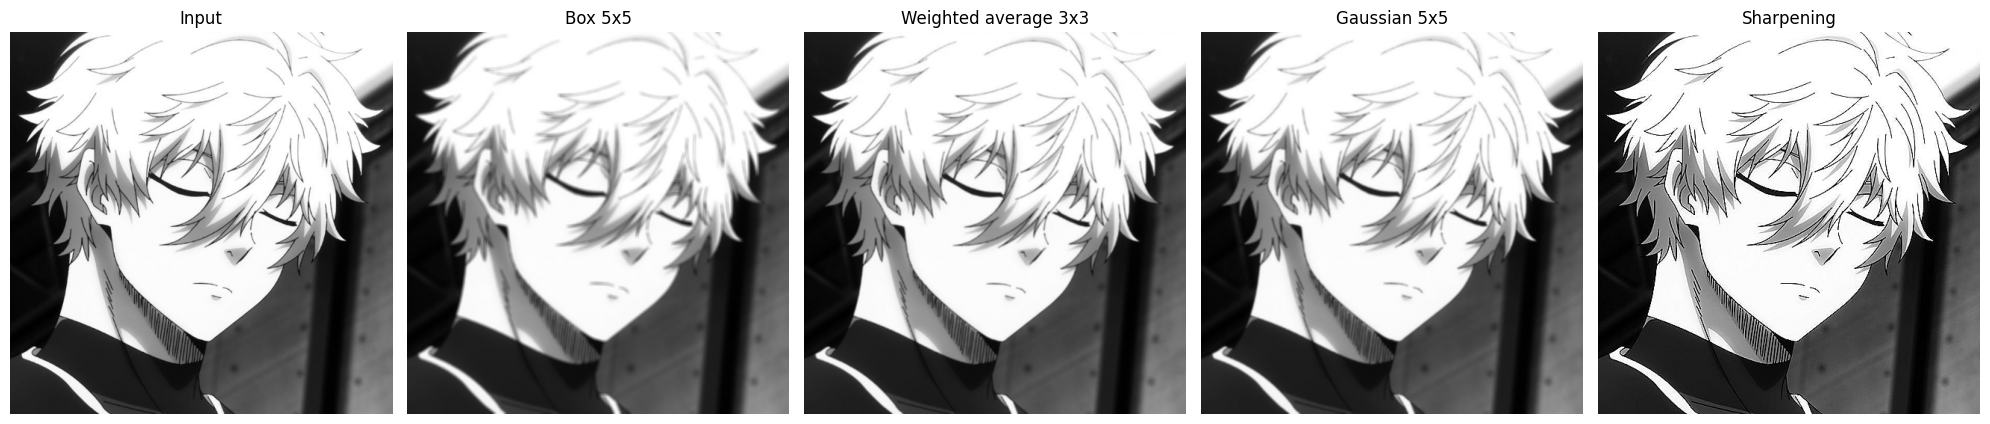

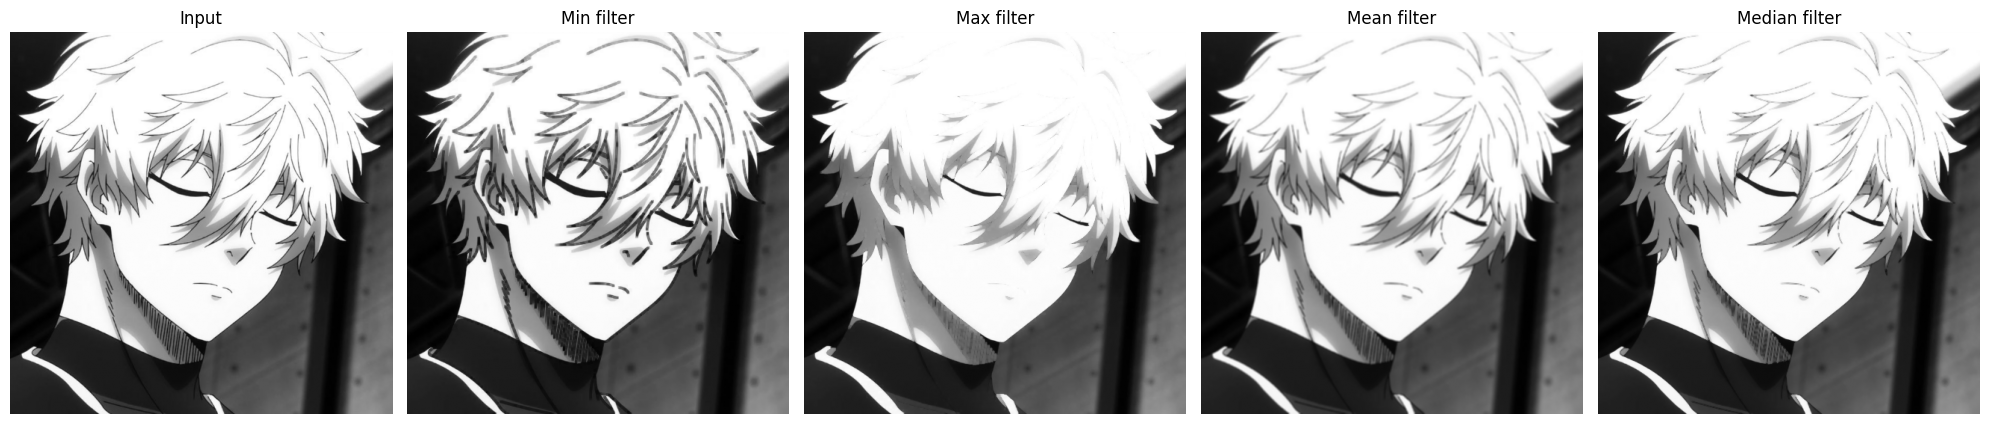

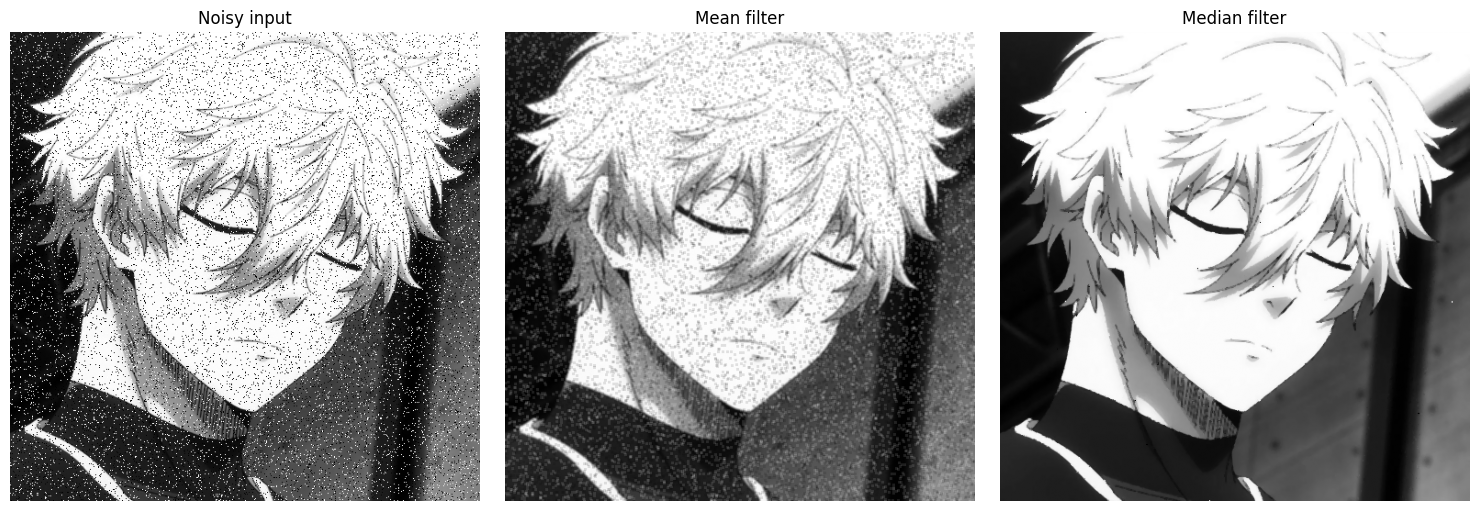

In [6]:
# ---------- a) Sobel operator ----------
sobel_x = cv2.Sobel(img, cv2.CV_64F, 1, 0, ksize=3)   # horizontal gradient
sobel_y = cv2.Sobel(img, cv2.CV_64F, 0, 1, ksize=3)   # vertical gradient
sobel_mag = np.clip(np.sqrt(sobel_x**2 + sobel_y**2), 0, 255).astype(np.uint8)
sobel_x_u8 = np.clip(np.abs(sobel_x), 0, 255).astype(np.uint8)
sobel_y_u8 = np.clip(np.abs(sobel_y), 0, 255).astype(np.uint8)

show([img, sobel_x_u8, sobel_y_u8, sobel_mag],
     ["Input", "Sobel X", "Sobel Y", "Sobel magnitude"],
     cols=4, save_as="task4a_sobel.png", figsize=(18, 5))

# ---------- b) Box filter ----------
box_k = np.ones((5, 5), np.float32) / 25
box = cv2.filter2D(img, -1, box_k)

# ---------- c) Weighted average filter ----------
wavg_k = np.array([[1, 2, 1],
                   [2, 4, 2],
                   [1, 2, 1]], np.float32) / 16
wavg = cv2.filter2D(img, -1, wavg_k)

# ---------- d) Gaussian filter mask ----------
g1d = cv2.getGaussianKernel(5, 1.0)
gauss_k = g1d @ g1d.T                      # 5x5 Gaussian mask
print("Gaussian mask (5x5, sigma=1):\n", np.round(gauss_k, 4))
gauss = cv2.filter2D(img, -1, gauss_k)

# ---------- e) Sharpening filter ----------
sharp_k = np.array([[ 0, -1,  0],
                    [-1,  5, -1],
                    [ 0, -1,  0]], np.float32)
sharp = cv2.filter2D(img, -1, sharp_k)

show([img, box, wavg, gauss, sharp],
     ["Input", "Box 5x5", "Weighted average 3x3", "Gaussian 5x5", "Sharpening"],
     cols=5, save_as="task4bcde.png", figsize=(20, 4.5))

# ---------- f) Min, Max, Mean, Median ----------
k = np.ones((3, 3), np.uint8)
min_f    = cv2.erode(img, k)               # minimum filter
max_f    = cv2.dilate(img, k)              # maximum filter
mean_f   = cv2.blur(img, (3, 3))           # mean filter
median_f = cv2.medianBlur(img, 3)          # median filter

show([img, min_f, max_f, mean_f, median_f],
     ["Input", "Min filter", "Max filter", "Mean filter", "Median filter"],
     cols=5, save_as="task4f_order_stat.png", figsize=(20, 4.5))

# Optional: add salt-and-pepper noise to see where median filtering shines
noisy = img.copy()
rng = np.random.default_rng(0)
n = int(0.05 * img.size)
noisy[rng.integers(0, h, n), rng.integers(0, w, n)] = 255
noisy[rng.integers(0, h, n), rng.integers(0, w, n)] = 0
show([noisy, cv2.blur(noisy, (3, 3)), cv2.medianBlur(noisy, 3)],
     ["Noisy input", "Mean filter", "Median filter"],
     cols=3, save_as="task4f_noise.png", figsize=(15, 5))

5. Laplacian, enhanced Laplacian, high-boost

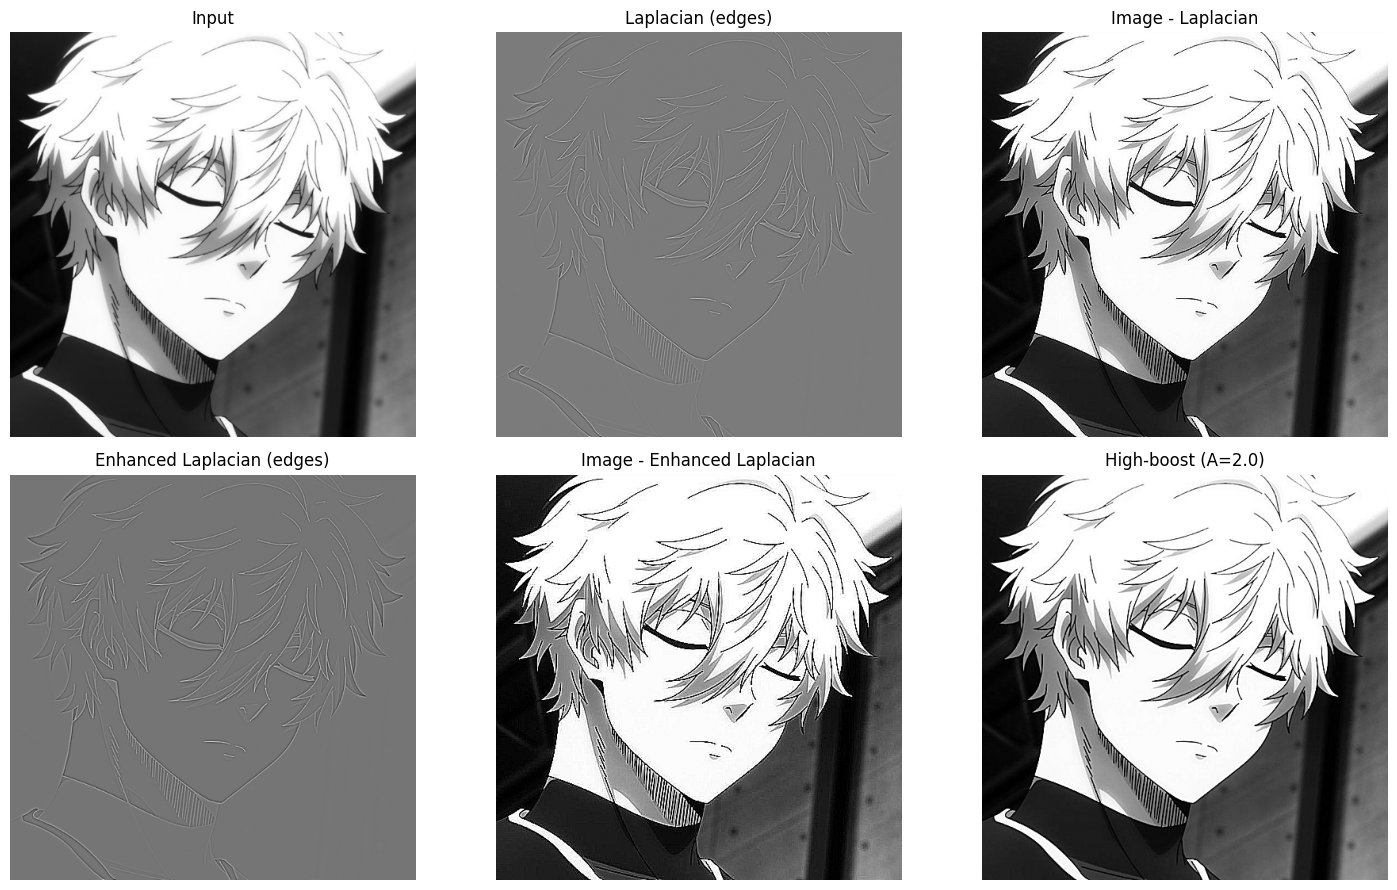

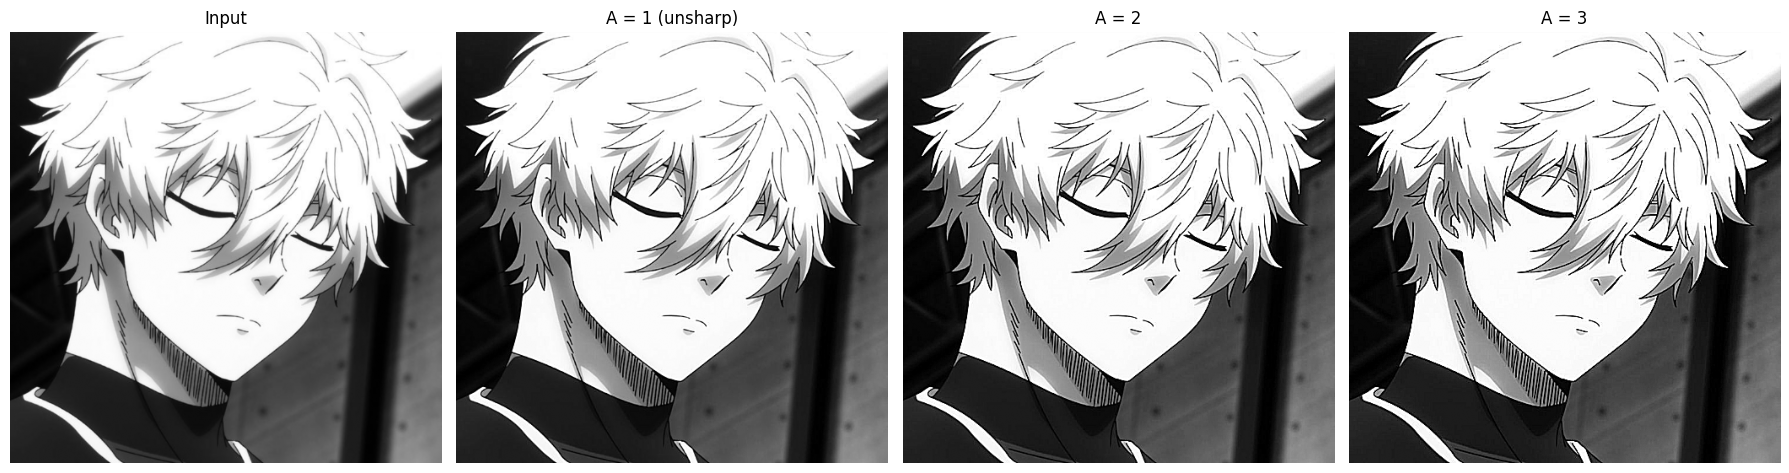

In [7]:
img_f = img.astype(np.float32)

# ---- Laplacian mask (center -4) ----
lap_k = np.array([[0,  1, 0],
                  [1, -4, 1],
                  [0,  1, 0]], np.float32)
lap = cv2.filter2D(img_f, -1, lap_k)
lap_sharp = np.clip(img_f - lap, 0, 255).astype(np.uint8)   # c = -1 since center is negative

# ---- Enhanced Laplacian mask (includes diagonals, center -8) ----
elap_k = np.array([[1,  1, 1],
                   [1, -8, 1],
                   [1,  1, 1]], np.float32)
elap = cv2.filter2D(img_f, -1, elap_k)
elap_sharp = np.clip(img_f - elap, 0, 255).astype(np.uint8)

# ---- High-boost filtering: g = f + A * (f - blurred) ----
blurred = cv2.GaussianBlur(img_f, (5, 5), 1.5)
unsharp_mask = img_f - blurred
A = 2.0                                        # boost factor (try 1.5, 2, 3)
high_boost = np.clip(img_f + A * unsharp_mask, 0, 255).astype(np.uint8)

# Scale the raw Laplacians to 0-255 so they are visible
def scale(x):
    x = x - x.min()
    return (255 * x / x.max()).astype(np.uint8)

show([img, scale(lap), lap_sharp, scale(elap), elap_sharp, high_boost],
     ["Input", "Laplacian (edges)", "Image - Laplacian",
      "Enhanced Laplacian (edges)", "Image - Enhanced Laplacian",
      f"High-boost (A={A})"],
     cols=3, save_as="task5_laplacian.png")

# Compare different high-boost factors
show([img] + [np.clip(img_f + a * unsharp_mask, 0, 255).astype(np.uint8) for a in (1, 2, 3)],
     ["Input", "A = 1 (unsharp)", "A = 2", "A = 3"],
     cols=4, save_as="task5_highboost_compare.png", figsize=(18, 5))